# 04 · Trustworthy: is each model's confidence honest? (Experiment 3)

Runs **locally on CPU in about a minute**. It needs no GPU, because it only reads the scores saved by notebook 03 (`runs/<model>/seed<k>/logits.npz`).

**Question:** when a model says it is *90 % sure*, is it right about 90 % of the time?

| Measure | What it tells us | Better |
|---|---|---|
| **ECE** (Expected Calibration Error) | average gap between *how sure* and *how right* | lower |
| **NLL** (negative log-likelihood) | penalises confident mistakes heavily | lower |
| **Brier score** | squared error of the probabilities | lower |
| **Temperature `T`** | `T > 1`: model was over-confident; `T < 1`: under-confident | close to 1 |
| **AURC** (area under risk–coverage) | error rate if the model may skip the tweets it is least sure about | lower |

**Fix tested:** temperature scaling (Guo et al., 2017). One number `T` is fitted on **validation**, and test logits are divided by it. Predictions, and so F1, never change; only the confidence does.

The notebook works with whatever runs exist, so it can be re-run once all 12 are finished.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import softmax

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
RUNS = ROOT / "runs"
FIG_DIR = ROOT / "results/figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from hinglish.data import load_splits, LABELS
from hinglish.calibration import ece_score, fit_temperature, apply_temperature, nll, plot_reliability

ORDER = ["tfidf_lr", "mbert", "xlmr", "muril", "hingbert", "hingbert_aug"]
NAMES = {"tfidf_lr": "TF-IDF + LR", "mbert": "mBERT", "xlmr": "XLM-R", "muril": "MuRIL", "hingbert": "HingBERT", "hingbert_aug": "HingBERT + aug"}
S = load_splits(ROOT / "data/processed")

## 1. Load the saved scores

* **Transformers:** every finished run of notebook 03.
* **TF-IDF baseline:** refitted here with the `C` chosen in notebook 02 (≈30 s), because notebook 02 did not save its scores. Its numbers must match `results/02_baseline_tfidf.json`.

In [2]:
runs = []
# notebook 03 runs + the spelling-augmented HingBERT runs from notebook 05
paths = [(p, None) for p in sorted(RUNS.glob("*/seed*/logits.npz"))]
paths += [(p, "hingbert_aug") for p in sorted((ROOT / "runs_robust/aug").glob("*/seed*/logits.npz"))]
for p, key in paths:
    r = json.loads((p.parent / "result.json").read_text())
    if key:
        r["model_key"] = key
    z = np.load(p, allow_pickle=True)
    runs.append(dict(model=r["model_key"], seed=r["seed"], val=z["val"], test=z["test"],
                     y_val=z["y_val"], y_test=z["y_test"], uid_test=z["uid_test"], val_wf1=r["val"]["weighted_f1"]))

# every run must be scored on the same tweets in the same order
assert all((r["uid_test"] == runs[0]["uid_test"]).all() for r in runs)
assert (runs[0]["uid_test"] == S["test"].uid.values).all()

print(f"{len(runs)} transformer runs found:")
print(pd.DataFrame([(r["model"], r["seed"]) for r in runs], columns=["model", "seed"]).groupby("model").seed.apply(list).to_string())

15 transformer runs found:
model
hingbert        [42, 43, 44]
hingbert_aug    [42, 43, 44]
mbert           [42, 43, 44]
muril           [42, 43, 44]
xlmr            [42, 43, 44]


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union
from sklearn.metrics import f1_score

base_json = json.loads((ROOT / "results/02_baseline_tfidf.json").read_text())
feats = make_union(
    TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, sublinear_tf=True, lowercase=True),
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, lowercase=True, max_features=200_000),
)
lr = make_pipeline(feats, LogisticRegression(C=base_json["best_C"], max_iter=3000)).fit(S["train"].text, S["train"].label_id)
base_run = dict(model="tfidf_lr", seed=0,
                val=lr.decision_function(S["val"].text), test=lr.decision_function(S["test"].text),
                y_val=S["val"].label_id.values, y_test=S["test"].label_id.values, uid_test=S["test"].uid.values)
f1 = f1_score(base_run["y_test"], base_run["test"].argmax(1), average="weighted")
print(f"baseline test wF1 {f1:.4f} (notebook 02: {base_json['test_weighted_f1']:.4f})")
assert abs(f1 - base_json["test_weighted_f1"]) < 1e-3
all_runs = [base_run] + runs

baseline test wF1 0.6872 (notebook 02: 0.6872)


## 2. Calibration of every run, before and after temperature scaling

`T` is always fitted on **validation** and judged on **test**.

In [4]:
def brier(p, y):
    return float(((p - np.eye(p.shape[1])[y]) ** 2).sum(1).mean())

def trust_metrics(r):
    lv, lt, yv, yt = r["val"], r["test"], r["y_val"], r["y_test"]
    T = fit_temperature(lv, yv)
    p0, p1 = softmax(lt, axis=1), apply_temperature(lt, T)
    return {"model": r["model"], "seed": r["seed"],
            "test wF1": f1_score(yt, lt.argmax(1), average="weighted"),
            "T": T,
            "ECE before": ece_score(p0, yt), "ECE after": ece_score(p1, yt),
            "NLL before": nll(lt, yt, 1.0), "NLL after": nll(lt, yt, T),
            "Brier before": brier(p0, yt), "Brier after": brier(p1, yt),
            "mean conf": p0.max(1).mean(), "accuracy": (lt.argmax(1) == yt).mean(),
            "val ECE before": ece_score(softmax(lv, axis=1), yv),
            "val ECE after": ece_score(apply_temperature(lv, T), yv)}

trust = pd.DataFrame([trust_metrics(r) for r in all_runs])
trust["model"] = pd.Categorical(trust.model, [m for m in ORDER if m in set(trust.model)])
trust = trust.sort_values(["model", "seed"]).reset_index(drop=True)
trust.round(4)

,model,seed,test wF1,T,ECE before,ECE after,NLL before,NLL after,Brier before,Brier after,mean conf,accuracy,val ECE before,val ECE after
0,tfidf_lr,0,0.6872,0.9322,0.0732,0.0605,0.7287,0.7215,0.4309,0.4275,0.6122,0.6853,0.0189,0.0144
1,mbert,42,0.6627,1.2496,0.0253,0.0527,0.7213,0.7368,0.4309,0.4366,0.6648,0.6693,0.0627,0.0295
2,mbert,43,0.6877,1.4395,0.0332,0.0565,0.7197,0.7311,0.4263,0.4305,0.7122,0.6853,0.0930,0.0257
3,mbert,44,0.6905,1.5544,0.0579,0.0584,0.7173,0.7262,0.4259,0.4263,0.7377,0.6930,0.1260,0.0338
4,xlmr,42,0.7162,1.5725,0.0503,0.0721,0.6755,0.6922,0.3983,0.4028,0.7514,0.7173,0.1236,0.0283
5,xlmr,43,0.7067,1.4914,0.0406,0.0630,0.6757,0.6929,0.3981,0.4044,0.7369,0.7053,0.1029,0.0290
6,xlmr,44,0.6997,1.5951,0.0638,0.0600,0.6870,0.6963,0.4076,0.4061,0.7645,0.7020,0.1335,0.0318
7,muril,42,0.7059,1.2130,0.0304,0.0652,0.7052,0.7211,0.4138,0.4212,0.6895,0.7050,0.0597,0.0181
8,muril,43,0.7022,1.2388,0.0445,0.0717,0.7051,0.7222,0.4143,0.4215,0.7003,0.7030,0.0694,0.0215
9,muril,44,0.7046,1.2440,0.0326,0.0610,0.7111,0.7256,0.4163,0.4223,0.7087,0.7047,0.0671,0.0156


In [5]:
cols = ["test wF1", "T", "ECE before", "ECE after", "NLL before", "NLL after", "Brier before", "Brier after"]
agg = trust.groupby("model", observed=True)[cols].agg(["mean", "std"])
summary = pd.DataFrame({c: agg[(c, "mean")].map("{:.4f}".format) + " ± " + agg[(c, "std")].fillna(0).map("{:.4f}".format) for c in cols})
summary["seeds"] = trust.groupby("model", observed=True).seed.count()
summary.index = [NAMES[m] for m in summary.index]
display(summary)
print("mean ± std over seeds (the TF-IDF baseline is deterministic, so std = 0)")

,test wF1,T,ECE before,ECE after,NLL before,NLL after,Brier before,Brier after,seeds
TF-IDF + LR,0.6872 ± 0.0000,0.9322 ± 0.0000,0.0732 ± 0.0000,0.0605 ± 0.0000,0.7287 ± 0.0000,0.7215 ± 0.0000,0.4309 ± 0.0000,0.4275 ± 0.0000,1
mBERT,0.6803 ± 0.0153,1.4145 ± 0.1540,0.0388 ± 0.0170,0.0559 ± 0.0029,0.7194 ± 0.0020,0.7314 ± 0.0053,0.4277 ± 0.0028,0.4311 ± 0.0052,3
XLM-R,0.7075 ± 0.0083,1.5530 ± 0.0546,0.0516 ± 0.0117,0.0650 ± 0.0063,0.6794 ± 0.0066,0.6938 ± 0.0022,0.4013 ± 0.0054,0.4044 ± 0.0016,3
MuRIL,0.7042 ± 0.0019,1.2319 ± 0.0166,0.0358 ± 0.0076,0.0659 ± 0.0054,0.7071 ± 0.0034,0.7229 ± 0.0023,0.4148 ± 0.0013,0.4217 ± 0.0005,3
HingBERT,0.7127 ± 0.0027,1.7989 ± 0.1623,0.1047 ± 0.0229,0.0490 ± 0.0070,0.6996 ± 0.0342,0.6734 ± 0.0126,0.4082 ± 0.0158,0.3916 ± 0.0072,3
HingBERT + aug,0.7258 ± 0.0071,1.4762 ± 0.2065,0.0560 ± 0.0243,0.0492 ± 0.0075,0.6383 ± 0.0293,0.6457 ± 0.0171,0.3784 ± 0.0161,0.3770 ± 0.0089,3


mean ± std over seeds (the TF-IDF baseline is deterministic, so std = 0)


### Over- or under-confident?

`mean confidence − accuracy` > 0 means the model claims more certainty than it earns.

In [6]:
gap = trust.assign(gap=trust["mean conf"] - trust["accuracy"]).groupby("model", observed=True)[["mean conf", "accuracy", "gap", "T"]].mean()
gap.index = [NAMES[m] for m in gap.index]
display(gap.round(4))

,mean conf,accuracy,gap,T
TF-IDF + LR,0.6122,0.6853,-0.0732,0.9322
mBERT,0.7049,0.6826,0.0224,1.4145
XLM-R,0.7509,0.7082,0.0427,1.5530
MuRIL,0.6995,0.7042,-0.0047,1.2319
HingBERT,0.8163,0.7121,0.1042,1.7989
HingBERT + aug,0.7697,0.7261,0.0435,1.4762


### Does the validation set transfer to test?

Temperature scaling assumes validation and test look alike. In this dataset they do not quite: every model scores several points **lower on val than on test** (the baseline: 0.624 vs 0.687). A `T` fitted on the harder val set can then over-correct on test. The table below checks this: val ECE always drops after scaling (it is fitted there), so if **test** ECE rises, the val→test gap is the reason.

In [7]:
shift = trust.groupby("model", observed=True)[["val ECE before", "val ECE after", "ECE before", "ECE after"]].mean()
shift["scaling helps on test?"] = np.where(shift["ECE after"] < shift["ECE before"], "yes", "no")
shift.index = [NAMES[m] for m in shift.index]
display(shift.round(4))

,val ECE before,val ECE after,ECE before,ECE after,scaling helps on test?
TF-IDF + LR,0.0189,0.0144,0.0732,0.0605,yes
mBERT,0.0939,0.0296,0.0388,0.0559,no
XLM-R,0.1200,0.0297,0.0516,0.0650,no
MuRIL,0.0654,0.0184,0.0358,0.0659,no
HingBERT,0.1529,0.0291,0.1047,0.0490,yes
HingBERT + aug,0.0996,0.0282,0.0560,0.0492,yes


## 3. Reliability diagrams

One run per model: the seed with the best **validation** F1, which is the checkpoint notebook 03 keeps. Bars on the diagonal = honest confidence; bars below it = over-confident.

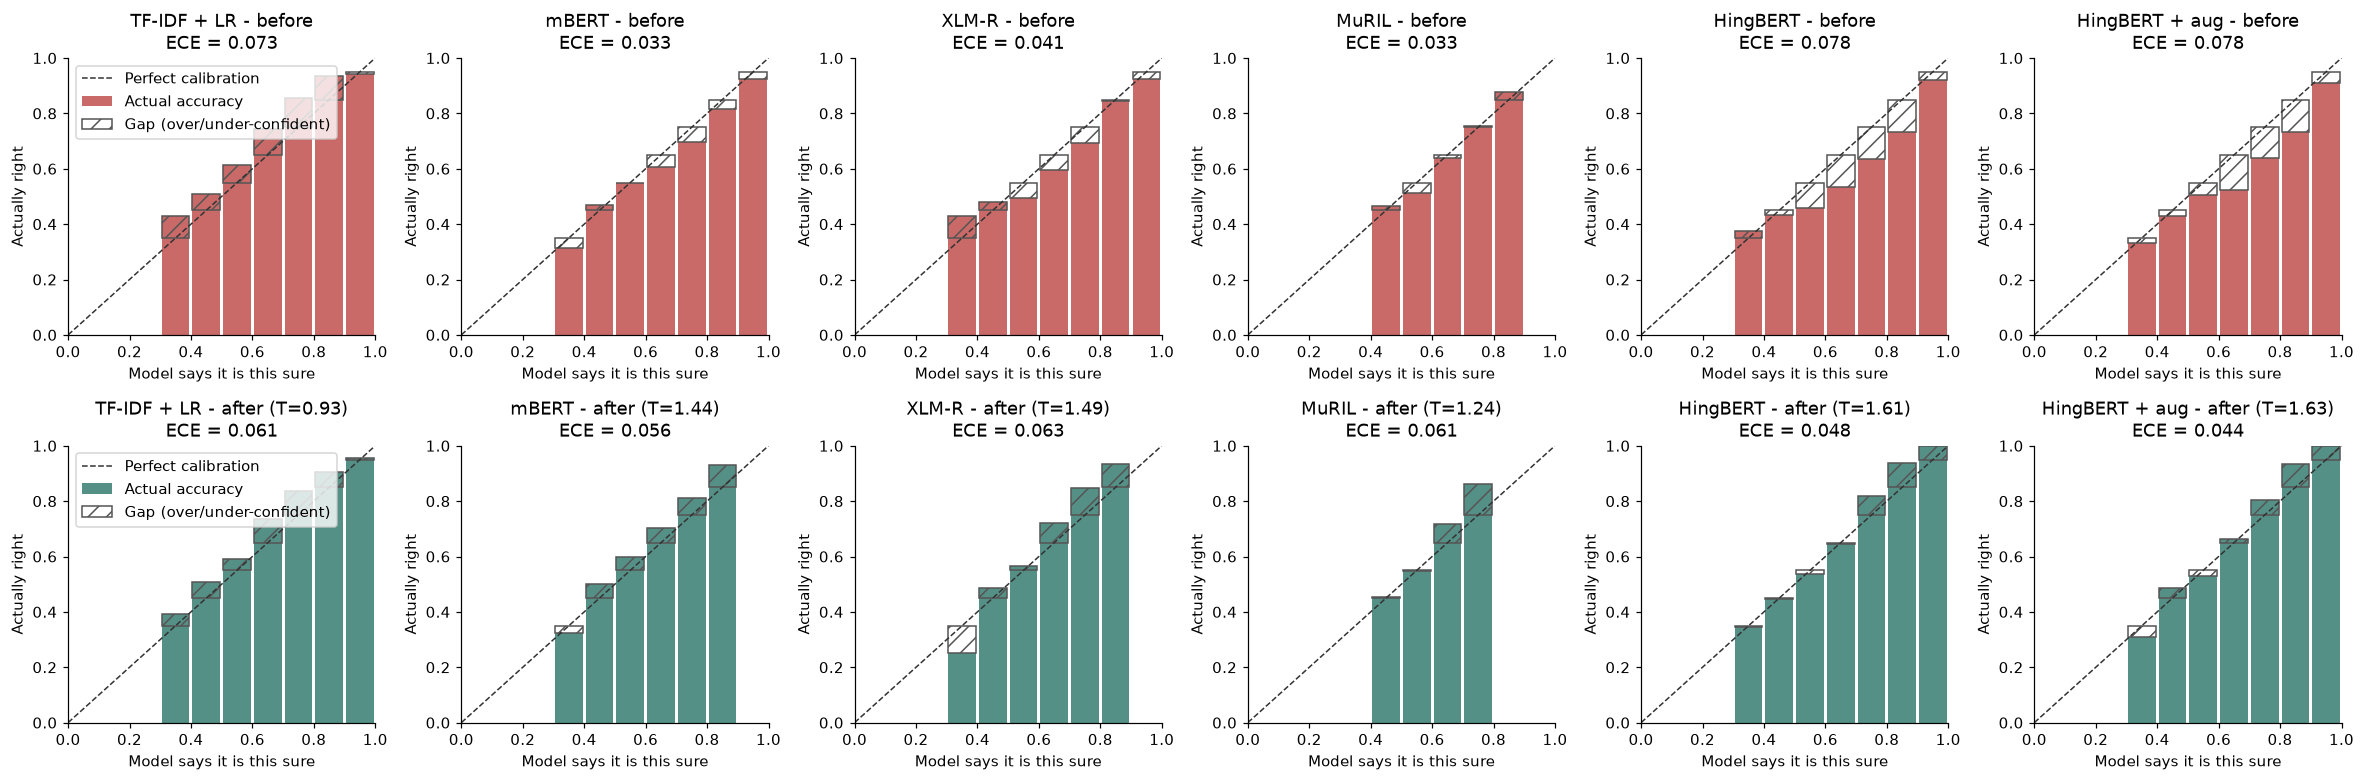

In [8]:
def best_run(m):
    cands = [r for r in all_runs if r["model"] == m]
    return max(cands, key=lambda r: r.get("val_wf1", 0))

models = [m for m in ORDER if any(r["model"] == m for r in all_runs)]
fig, axes = plt.subplots(2, len(models), figsize=(3.6 * len(models), 7.2), squeeze=False)
for j, m in enumerate(models):
    r = best_run(m)
    T = fit_temperature(r["val"], r["y_val"])
    plot_reliability(axes[0, j], softmax(r["test"], axis=1), r["y_test"], f"{NAMES[m]} - before", color="#C0504D")
    plot_reliability(axes[1, j], apply_temperature(r["test"], T), r["y_test"], f"{NAMES[m]} - after (T={T:.2f})", color="#377D72")
    for ax in axes[:, j]:
        ax.legend().set_visible(j == 0)
plt.tight_layout(); plt.savefig(FIG_DIR / "04_reliability_all.png"); plt.show()

## 4. Selective prediction: can the model know when to skip?

A trustworthy model's **least confident** tweets should be the ones it gets wrong. If we let it skip the bottom *x* % by confidence, accuracy on the rest should rise. **AURC** summarises the whole curve (lower = better ordering of its own confidence). Temperature scaling does not change this ordering, so AURC is the same before and after.

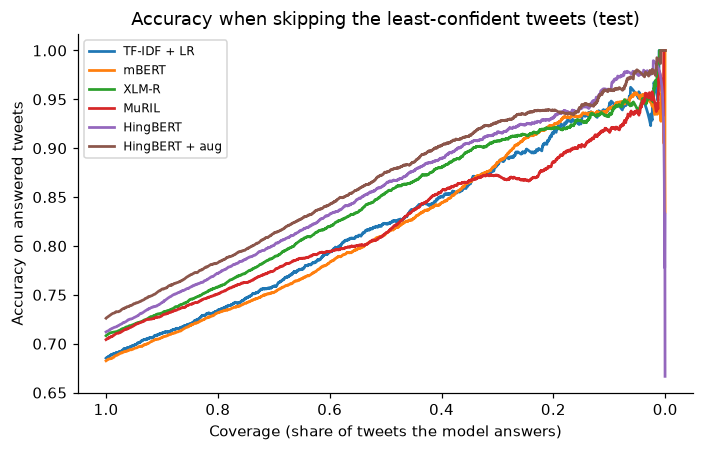

,AURC,acc @100%,acc @80%,acc @50%
model,,,,
TF-IDF + LR,0.1766,0.6853,0.7342,0.8227
mBERT,0.1799,0.6826,0.7317,0.8122
XLM-R,0.1563,0.7082,0.7579,0.8547
MuRIL,0.1774,0.7042,0.7508,0.8129
HingBERT,0.1445,0.7121,0.7722,0.8633
HingBERT + aug,0.1352,0.7261,0.7829,0.8751


In [9]:
def risk_coverage(logits, y):
    conf = softmax(logits, axis=1).max(1)
    order = np.argsort(-conf)
    err = (logits.argmax(1) != y)[order].astype(float)
    cov = np.arange(1, len(y) + 1) / len(y)
    risk = np.cumsum(err) / np.arange(1, len(y) + 1)
    return cov, risk

rows = []
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for m in models:
    rs = [r for r in all_runs if r["model"] == m]
    curves = [risk_coverage(r["test"], r["y_test"]) for r in rs]
    cov, risk = curves[0][0], np.mean([c[1] for c in curves], axis=0)
    ax.plot(cov, 1 - risk, label=NAMES[m], lw=1.8)
    for r, (c, rk) in zip(rs, curves):
        k = lambda f: 1 - rk[int(f * len(rk)) - 1]
        rows.append({"model": NAMES[m], "seed": r["seed"], "AURC": rk.mean(),
                     "acc @100%": k(1.0), "acc @80%": k(0.8), "acc @50%": k(0.5)})
ax.set_xlabel("Coverage (share of tweets the model answers)"); ax.set_ylabel("Accuracy on answered tweets")
ax.set_title("Accuracy when skipping the least-confident tweets (test)"); ax.invert_xaxis(); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "04_risk_coverage.png"); plt.show()

sel = pd.DataFrame(rows).groupby("model", sort=False).mean(numeric_only=True).drop(columns="seed")
display(sel.round(4))

## 5. Is confidence less honest on heavily code-mixed tweets?

This links the trust study to robustness. Test tweets are split into three equal groups by **code-mixing index (CMI)**: how evenly Hindi and English are mixed. Each model's ECE is measured inside each group (best-val seed, before scaling).

In [10]:
te = S["test"].reset_index(drop=True)
te["cmi_group"] = pd.qcut(te.cmi, 3, labels=["low mix", "medium mix", "high mix"])
rows = []
for m in models:
    r = best_run(m)
    p = softmax(r["test"], axis=1)
    for g, idx in te.groupby("cmi_group", observed=True).groups.items():
        idx = np.asarray(idx)
        yt = r["y_test"][idx]
        rows.append({"model": NAMES[m], "group": g, "n": len(idx),
                     "accuracy": (p[idx].argmax(1) == yt).mean(), "ECE": ece_score(p[idx], yt)})
by_cmi = pd.DataFrame(rows)
display(by_cmi.pivot(index="model", columns="group", values="ECE").loc[[NAMES[m] for m in models], ["low mix", "medium mix", "high mix"]].round(4))
display(by_cmi.pivot(index="model", columns="group", values="accuracy").loc[[NAMES[m] for m in models], ["low mix", "medium mix", "high mix"]].round(4))
print("groups have ~1000 tweets each, so ECE differences below ~0.02 are within noise")

group,low mix,medium mix,high mix
model,,,
TF-IDF + LR,0.0591,0.0672,0.0945
mBERT,0.0395,0.0405,0.0474
XLM-R,0.0365,0.0568,0.0457
MuRIL,0.0519,0.0284,0.0256
HingBERT,0.0851,0.0903,0.0663
HingBERT + aug,0.0788,0.0915,0.0758


group,low mix,medium mix,high mix
model,,,
TF-IDF + LR,0.6643,0.6804,0.7118
mBERT,0.6653,0.6932,0.6976
XLM-R,0.7093,0.6814,0.7261
MuRIL,0.6913,0.6971,0.7261
HingBERT,0.6963,0.7158,0.7363
HingBERT + aug,0.7083,0.7168,0.7352


groups have ~1000 tweets each, so ECE differences below ~0.02 are within noise


## 6. Bonus: averaging the 3 seeds (a small ensemble)

Averaging the probabilities of independently trained models is a known way to get more honest confidence (Lakshminarayanan et al., 2017). It costs 3× the compute, which matters for the **Efficient** study.

In [11]:
rows = []
for m in models:
    rs = [r for r in all_runs if r["model"] == m]
    if len(rs) < 2:
        continue
    yv, yt = rs[0]["y_val"], rs[0]["y_test"]
    # average log-probabilities so the result is again a set of logits that temperature scaling can use
    lv = np.mean([np.log(softmax(r["val"], axis=1)) for r in rs], axis=0)
    lt = np.mean([np.log(softmax(r["test"], axis=1)) for r in rs], axis=0)
    pt = np.mean([softmax(r["test"], axis=1) for r in rs], axis=0)
    T = fit_temperature(lv, yv)
    single = trust[trust.model == m]
    rows.append({"model": NAMES[m], "seeds": len(rs),
                 "single wF1 (mean)": single["test wF1"].mean(), "ensemble wF1": f1_score(yt, pt.argmax(1), average="weighted"),
                 "single ECE (mean)": single["ECE before"].mean(), "ensemble ECE": ece_score(pt, yt),
                 "ensemble ECE after T": ece_score(apply_temperature(lt, T), yt)})
ens = pd.DataFrame(rows).set_index("model") if rows else pd.DataFrame()
display(ens.round(4))

,seeds,single wF1 (mean),ensemble wF1,single ECE (mean),ensemble ECE,ensemble ECE after T
model,,,,,,
mBERT,3,0.6803,0.6974,0.0388,0.0273,0.0641
XLM-R,3,0.7075,0.7109,0.0516,0.0371,0.0622
MuRIL,3,0.7042,0.7096,0.0358,0.0460,0.0674
HingBERT,3,0.7127,0.7131,0.1047,0.0966,0.0515
HingBERT + aug,3,0.7258,0.7246,0.0560,0.0449,0.0503


## 7. Save results for the final comparison table

In [12]:
out = ROOT / "results"
trust.drop(columns=[]).to_csv(out / "04_trust_runs.csv", index=False)
summary.to_csv(out / "04_trust_summary.csv")
sel.to_csv(out / "04_selective_prediction.csv")
by_cmi.to_csv(out / "04_trust_by_cmi.csv", index=False)
if len(ens):
    ens.to_csv(out / "04_seed_ensemble.csv")
print("saved:", *sorted(p.name for p in out.glob("04_*")), sep="\n  ")

saved:
  04_seed_ensemble.csv
  04_selective_prediction.csv
  04_trust_by_cmi.csv
  04_trust_runs.csv
  04_trust_summary.csv


## Takeaways (all 12 transformer runs, test set)

* **Accuracy and honesty don't go together.** **HingBERT** is the most accurate (wF1 0.713 ± 0.003) but the **most over-confident** (mean confidence 0.82 vs accuracy 0.71; ECE 0.105; T = 1.80). **MuRIL** is the most honest out of the box (ECE 0.036; confidence ≈ accuracy; T = 1.23) but about 1 point less accurate.
* **Temperature scaling is not reliable on this dataset.** It always fixes validation (ECE → 0.02–0.03), but on test it helps only HingBERT (0.105 → **0.049**) and TF-IDF. It makes mBERT, XLM-R and MuRIL **worse**, because val is harder than test, so `T` over-corrects. After scaling, every transformer lands at ECE ≈ 0.05–0.07, and HingBERT ends up the best calibrated.
* **HingBERT knows best when to skip.** It has the lowest AURC (0.145). Answering only its 50 % most confident tweets gives **86 % accuracy** (vs 82 % for TF-IDF). Its raw probabilities are too high, but their *ranking* is the most useful.
* **Heavier code-mixing doesn't make transformers less honest.** No consistent ECE pattern across CMI groups; all models are actually *more* accurate on high-mix tweets. Only TF-IDF's calibration worsens with mixing (0.059 → 0.095).
* **The 3-seed ensemble helps little.** +1.7 F1 points for mBERT, under +0.6 for the others, and it doesn't fix HingBERT's overconfidence (ECE 0.097), at 3× the cost.

* **Spelling augmentation (notebook 05) fixes most of HingBERT's overconfidence.** ECE 0.105 → **0.056**, T 1.80 → 1.48, confidence 0.77 vs accuracy 0.73. It also gives the best AURC (**0.135**; 87.5 % accuracy on its 50 % most confident tweets) and the best NLL and Brier of all models. After scaling it matches plain HingBERT (0.049).

**Decision (updated after notebook 05):** the **spelling-augmented HingBERT, seed 43**, is the teacher for the Efficient study. Earlier decision: HingBERT seed 43 (best on val) is the **teacher for the Efficient study**: most accurate, smallest (110 M parameters), best AURC, and best ECE after scaling. **Trust numbers the compressed model must keep:** ECE after scaling ≈ 0.05, AURC ≈ 0.135–0.145.

**Next:** Robust (respelled Hindi words), then Efficient (vocab trim → distil → int8), re-checking ECE and AURC on the compressed model.